# Lapse-rate feedback in a single column

The increase of outgoing longwave radiation (OLR) for a given surface warming depends on where in the column the atmosphere warms. Two clear-sky columns, the AFGL tropical (`afglt`) and sub-arctic winter (`afglsw`) atmospheres, get three thermal runs each:

1. **base**: the unperturbed profile;
2. **Planck**: surface and every level warmed by $\Delta T_s = 1$ K;
3. **lapse rate**: the same 1 K surface warming with a region-typical vertical pattern.

Specific humidity and all other gas mixing ratios stay fixed; heights are recomputed hydrostatically, so each layer keeps its gas mass. Sign convention: a positive feedback amplifies warming.

$$
\lambda_\mathrm{P} = -\frac{\Delta\mathrm{OLR}_\mathrm{P}}{\Delta T_s}, \qquad
\lambda_\mathrm{LR} = -\frac{\Delta\mathrm{OLR}_\mathrm{LR} - \Delta\mathrm{OLR}_\mathrm{P}}{\Delta T_s}.
$$

Atmosphere files: {doc}`/guide/atmosphere`. The moist adiabat needs `metpy`.

In [1]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import metpy.calc as mpcalc
import numpy as np
import pandas as pd
import xarray as xr
from metpy.units import units

import pyradtran
from pyradtran import Var, load_config

logging.getLogger("pyradtran").setLevel(logging.CRITICAL)

CONFIG = Path("config/lapse_rate_feedback_thermal.yaml")  # disort, reptran coarse, 3-100 um, integrated
ATMMOD = Path(load_config(CONFIG).paths.libradtran_data) / "atmmod"
WORK = Path("pyradtran_work/lapse_rate")
WORK.mkdir(parents=True, exist_ok=True)

RD, G0 = 287.058, 9.80665  # J kg-1 K-1, m s-2
DTS = 1.0                  # surface warming (K)


def read_afgl(name):
    """AFGL profile, rows top-down: z (km), p (hPa), T (K), air, O3, O2, H2O, CO2, NO2 (cm-3)."""
    return np.loadtxt(ATMMOD / f"{name}.dat")


def write_profile(base, dT, path):
    """Write `base` warmed by dT at fixed pressure and fixed mixing ratios; return (z, T)."""
    p, T = base[:, 1], base[:, 2] + dT
    dens = base[:, 3:] * (base[:, 2] / T)[:, None]  # n = p / kT, mixing ratios unchanged
    dz = RD / G0 * 0.5 * (T[:-1] + T[1:]) * np.log(p[1:] / p[:-1]) / 1e3  # hypsometric, km
    z = base[-1, 0] + np.concatenate([np.cumsum(dz[::-1])[::-1], [0.0]])
    np.savetxt(path, np.column_stack([z, p, T, dens]), fmt="%12.5g")
    return z, T

## Warming patterns

- **Tropics**: convection keeps the troposphere near a moist adiabat. The warming is the difference of two pseudo-adiabats from a saturated surface parcel at $T_s$ and $T_s + 1$ K, up to 100 hPa (≈ 16 km); it peaks at ≈ 3.2 K near 180 hPa.
- **Arctic**: a stable boundary layer keeps the warming near the surface: 1 K at the surface, falling linearly to 0.5 K at 3 km, 0.5 K up to the tropopause (9 km).

Above the tropopause both warmed runs use +1 K.

In [2]:
def tropical_pattern(base, p_top=100.0):
    p = base[:, 1] * units.hPa
    trop = base[:, 1] >= p_top
    T0 = base[-1, 2] * units.K
    moist = lambda t: mpcalc.moist_lapse(p[trop][::-1], t, reference_pressure=p[-1])
    dT = np.full(len(p), DTS)
    dT[trop] = (moist(T0 + DTS * units.K) - moist(T0)).m_as("K")[::-1]
    return dT


def arctic_pattern(base, z_trop=9.0, h=3.0, f=0.5):
    z = base[:, 0] - base[-1, 0]
    dT = DTS * (f + (1 - f) * np.clip(1 - z / h, 0, 1))
    return np.where(z > z_trop, DTS, dT)


regions = {"tropics": ("afglt", tropical_pattern), "arctic": ("afglsw", arctic_pattern)}
runs, profiles = [], {}
for region, (name, pattern) in regions.items():
    base = read_afgl(name)
    for case, dT in {"base": np.zeros(len(base)), "planck": np.full(len(base), DTS),
                     "lapse_rate": pattern(base)}.items():
        path = WORK / f"{region}_{case}.dat"
        profiles[region, case] = write_profile(base, dT, path) + (dT,)
        runs.append({"region": region, "case": case, "atm": str(path.resolve()),
                     "ts": base[-1, 2] + dT[-1]})
runs = pd.DataFrame(runs)
runs[["region", "case", "ts"]]

,region,case,ts
0,tropics,base,299.7
1,tropics,planck,300.7
2,tropics,lapse_rate,300.7
3,arctic,base,257.2
4,arctic,planck,258.2
5,arctic,lapse_rate,258.2


## Run and diagnose

One run per row, with atmosphere file and surface temperature taken from the dataset via `Var`. The surface is a blackbody (`albedo 0`) at the lowest-level air temperature.

In [3]:
n = len(runs)
ds = xr.Dataset(
    {"atm": ("run", runs["atm"]), "ts": ("run", runs["ts"])},
    coords={"time": ("run", np.full(n, np.datetime64("2000-01-01"))),
            "latitude": ("run", np.zeros(n)), "longitude": ("run", np.zeros(n))},
)
res = ds.pyradtran.run(
    config_path=CONFIG,
    params={"atmosphere_file": Var("atm"), "sur_temperature": Var("ts"), "zout": "toa"},
    save_to_file=False,
    show_progress=False,
)
runs["olr"] = res["eup"].squeeze("altitude").values  # W m-2

olr = runs.pivot(index="region", columns="case", values="olr").loc[["tropics", "arctic"]]
summary = pd.DataFrame({
    "OLR base (W m-2)": olr["base"],
    "dOLR Planck (W m-2)": olr["planck"] - olr["base"],
    "dOLR lapse rate (W m-2)": olr["lapse_rate"] - olr["base"],
    "lambda_P (W m-2 K-1)": -(olr["planck"] - olr["base"]) / DTS,
    "lambda_LR (W m-2 K-1)": -(olr["lapse_rate"] - olr["planck"]) / DTS,
})
summary.round(2)

,OLR base (W m-2),dOLR Planck (W m-2),dOLR lapse rate (W m-2),lambda_P (W m-2 K-1),lambda_LR (W m-2 K-1)
region,,,,,
tropics,284.72,4.21,6.07,-4.21,-1.86
arctic,196.90,3.21,2.64,-3.21,0.57


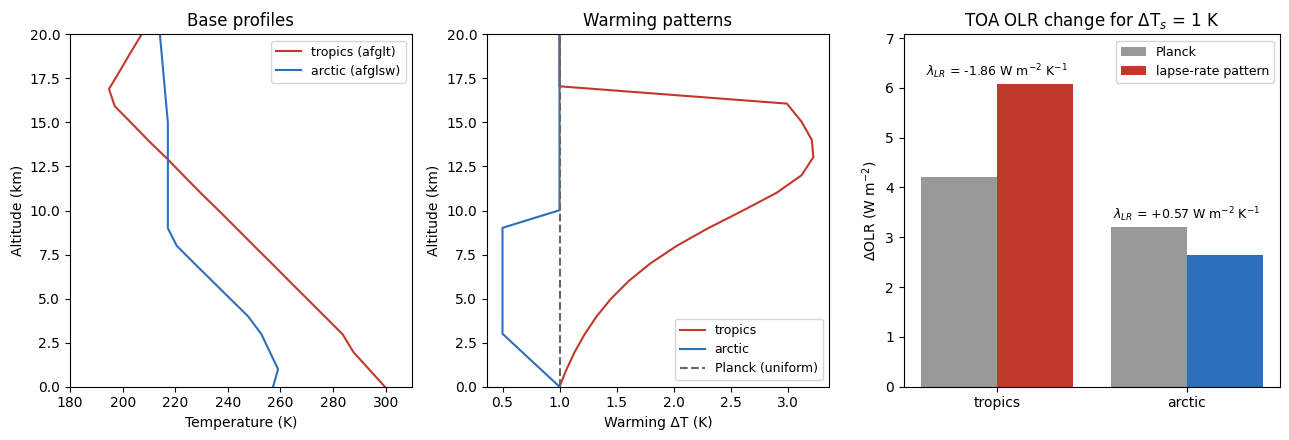

In [4]:
colors = {"tropics": "#c0392b", "arctic": "#2c6fbb"}
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4.5), width_ratios=[1, 1, 1.1])

for region, c in colors.items():
    z, T, _ = profiles[region, "base"]
    ax1.plot(T, z, color=c, label=f"{region} ({regions[region][0]})")
    ax2.plot(profiles[region, "lapse_rate"][2], profiles[region, "lapse_rate"][0], color=c, label=region)
ax1.set_xlim(180, 310)
ax2.axvline(DTS, color="0.4", ls="--", label="Planck (uniform)")
for ax, xlabel, title in [(ax1, "Temperature (K)", "Base profiles"),
                          (ax2, "Warming ΔT (K)", "Warming patterns")]:
    ax.set(ylim=(0, 20), xlabel=xlabel, ylabel="Altitude (km)", title=title)
    ax.legend(fontsize=9)

x = np.arange(2)
ax3.bar(x - 0.2, summary["dOLR Planck (W m-2)"], 0.4, color="0.6", label="Planck")
ax3.bar(x + 0.2, summary["dOLR lapse rate (W m-2)"], 0.4, color=[colors[r] for r in summary.index],
        label="lapse-rate pattern")
for i, lam in enumerate(summary["lambda_LR (W m-2 K-1)"]):
    ax3.text(i, summary.iloc[i, 1:3].max() + 0.15, f"$\\lambda_{{LR}}$ = {lam:+.2f} W m$^{{-2}}$ K$^{{-1}}$", ha="center", fontsize=9)
ax3.set(xticks=x, xticklabels=summary.index, ylabel="ΔOLR (W m$^{-2}$)",
        title=f"TOA OLR change for ΔT$_s$ = {DTS:g} K", ylim=(0, summary.iloc[:, 1:3].values.max() + 1))
ax3.legend(fontsize=9, loc="upper right")
plt.tight_layout()

## Interpretation

Uniform warming raises the OLR by 4.2 W m⁻² (tropics) and 3.2 W m⁻² (Arctic), i.e. $\lambda_\mathrm{P}$ = −4.2 and −3.2 W m⁻² K⁻¹; the colder column emits less per kelvin.

- **Tropics**: the upper troposphere, which emits most of the OLR, warms 2–3 times more than the surface. The OLR rises 1.9 W m⁻² more than under uniform warming: $\lambda_\mathrm{LR} = -1.9$ W m⁻² K⁻¹, a **negative** feedback.
- **Arctic**: the free troposphere warms half as much as the surface. The OLR rises 0.6 W m⁻² less than under uniform warming: $\lambda_\mathrm{LR} = +0.6$ W m⁻² K⁻¹, a **positive** feedback that contributes to Arctic amplification (Pithan and Mauritsen, 2014).

Both signs match the standard result. The magnitudes follow from the imposed patterns; the tropical value is at the strong end because the column follows a saturated pseudo-adiabat up to 100 hPa. `reptran medium` gives the same feedbacks within 0.01 W m⁻² K⁻¹.

**Caveats.** Single clear-sky column, idealised warming patterns, fixed specific humidity (no water-vapour feedback, which partly offsets the tropical lapse-rate feedback), uniform stratospheric warming without adjustment, longwave only. Climate-model analyses use radiative kernels on 3-D fields (Soden and Held, 2006).

**References.** Pithan, F. and Mauritsen, T. (2014): Arctic amplification dominated by temperature feedbacks in contemporary climate models, *Nat. Geosci.*, 7, 181–184, doi:10.1038/ngeo2071. Soden, B. J. and Held, I. M. (2006): An assessment of climate feedbacks in coupled ocean–atmosphere models, *J. Climate*, 19, 3354–3360, doi:10.1175/JCLI3799.1.